## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=tp0cW0CD11Hi&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [6.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

### 1.1 Import Libraries

In [1]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1.2 Set Working Directory & File Paths (Local Environment)

In [2]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print(f"All files exist and path is correctly set: {current_dir}")
else:
    print("Some files are missing or path is not correctly set.")
    print(f"Current directory: {current_dir}")

All files exist and path is correctly set: /Users/arkarchanmyae/Desktop/projects/gci-competition


## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

In [3]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

### 2.2 Selecting Features

It is often difficult to perform data analysis and preprocessing on all features from the beginning. Instead, an easier way to get started is to start with a small number of features and then add features one by one.

This notebook will focus on 5 features. For the remaining 25 types of features, please refer to the lecture materials, the methods introduced in this notebook, etc., and perform the analysis on your own.

Feel free to also ask questions in lectures, office hours, or in the Slack community!

In [ ]:
# =============================================================
# ALL COLUMNS FROM HomeCredit_columns_description.xlsx
# Categorized by type for ML model training reference
# =============================================================

# --- ID / TARGET (not used as features) ---
# SK_ID_CURR          : ID of loan in our sample
# TARGET              : Target variable (1 = payment difficulties, 0 = other)

# --- NUMERICAL: Continuous (financial amounts) ---
# AMT_INCOME_TOTAL    : Income of the client
# AMT_CREDIT          : Credit amount of the loan
# AMT_ANNUITY         : Loan annuity
# AMT_GOODS_PRICE     : Price of the goods the loan is given for
# OWN_CAR_AGE         : Age of client's car
# REGION_POPULATION_RELATIVE : Normalized population of region where client lives
# EXT_SOURCE_1        : Normalized score from external data source
# EXT_SOURCE_2        : Normalized score from external data source
# EXT_SOURCE_3        : Normalized score from external data source

# --- NUMERICAL: Days / Time-based (negative values = days before application) ---
# DAYS_BIRTH          : Client's age in days at the time of application
# DAYS_EMPLOYED       : Days before application since current employment started
# DAYS_REGISTRATION   : Days before application when client changed registration
# DAYS_ID_PUBLISH     : Days before application when client changed identity document
# DAYS_LAST_PHONE_CHANGE : Days before application when client changed phone

# --- NUMERICAL: Count-based (integers) ---
# CNT_CHILDREN        : Number of children the client has
# CNT_FAM_MEMBERS     : How many family members does client have
# REGION_RATING_CLIENT: Our rating of the region where client lives (1, 2, 3)
# AMT_REQ_CREDIT_BUREAU_HOUR : Enquiries to Credit Bureau 1 hour before application
# AMT_REQ_CREDIT_BUREAU_MON  : Enquiries to Credit Bureau 1 month before application
# AMT_REQ_CREDIT_BUREAU_QRT  : Enquiries to Credit Bureau 3 months before application
# AMT_REQ_CREDIT_BUREAU_YEAR : Enquiries to Credit Bureau 1 year before application

# --- CATEGORICAL: Nominal (needs Label/One-Hot Encoding) ---
# NAME_CONTRACT_TYPE  : Cash loan or revolving loan
# CODE_GENDER         : Gender of the client
# NAME_INCOME_TYPE    : Client's income type (businessman, working, maternity leave...)
# NAME_EDUCATION_TYPE : Highest education level achieved
# NAME_FAMILY_STATUS  : Family status of the client
# NAME_HOUSING_TYPE   : Housing situation (renting, living with parents...)
# OCCUPATION_TYPE     : Type of occupation of the client
# ORGANIZATION_TYPE   : Type of organization where client works

# --- BINARY: Flag columns (0 = NO, 1 = YES) ---
# FLAG_MOBIL          : Did client provide mobile phone?
# FLAG_EMP_PHONE      : Did client provide work phone?
# FLAG_WORK_PHONE     : Did client provide home phone?


In [ ]:
# Focus on 5 features
use_features = [
    "NAME_CONTRACT_TYPE",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "CNT_FAM_MEMBERS",
    # "CNT_CHILDREN",
    # "NAME_FAMILY_STATUS",
    # "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "OWN_CAR_AGE",
    "ORGANIZATION_TYPE",
    # add new features to use here
]
target = train["TARGET"].values

train = train[use_features]
train["TARGET"] = target
test = test[use_features]

Let's check the data once again.

In [6]:
# Check train data shape
print(f"train shape: {train.shape}")
train.head(5)

train shape: (171202, 10)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,CNT_FAM_MEMBERS,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,TARGET
0,Cash loans,112500.0,755190.0,36328.5,675000.0,2.0,0.372591,NaN,School,0
1,Cash loans,225000.0,585000.0,16893.0,585000.0,2.0,0.449567,NaN,XNA,0
2,Cash loans,54000.0,334152.0,18256.5,270000.0,2.0,0.569503,NaN,Postal,0
3,Cash loans,67500.0,152820.0,8901.0,135000.0,1.0,0.105235,NaN,XNA,0
4,Cash loans,157500.0,271066.5,21546.0,234000.0,2.0,0.202490,NaN,Business Entity Type 3,1


In [7]:
# Check train data info
print(f"train info: {train.info()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   NAME_CONTRACT_TYPE  171202 non-null  object 
 1   AMT_INCOME_TOTAL    171202 non-null  float64
 2   AMT_CREDIT          171202 non-null  float64
 3   AMT_ANNUITY         171202 non-null  float64
 4   AMT_GOODS_PRICE     171202 non-null  float64
 5   CNT_FAM_MEMBERS     171200 non-null  float64
 6   EXT_SOURCE_2        170833 non-null  float64
 7   OWN_CAR_AGE         58210 non-null   float64
 8   ORGANIZATION_TYPE   171202 non-null  object 
 9   TARGET              171202 non-null  int64  
dtypes: float64(7), int64(1), object(2)
memory usage: 13.1+ MB
train info: None


In [8]:
# Check train data describe
print(f"train describe: {train.describe()}")

train describe:        AMT_INCOME_TOTAL    AMT_CREDIT    AMT_ANNUITY  AMT_GOODS_PRICE  \
count      1.712020e+05  1.712020e+05  171202.000000     1.712020e+05   
mean       1.683712e+05  5.991293e+05   27120.065953     5.380569e+05   
std        1.072348e+05  4.028170e+05   14450.252689     3.685727e+05   
min        2.610000e+04  4.500000e+04    1980.000000     4.500000e+04   
25%        1.125000e+05  2.700000e+05   16546.500000     2.385000e+05   
50%        1.462500e+05  5.146020e+05   24916.500000     4.500000e+05   
75%        2.025000e+05  8.086500e+05   34600.500000     6.795000e+05   
max        1.350000e+07  4.050000e+06  170986.500000     2.254500e+06   

       CNT_FAM_MEMBERS  EXT_SOURCE_2   OWN_CAR_AGE         TARGET  
count    171200.000000  1.708330e+05  58210.000000  171202.000000  
mean          2.152331  5.145083e-01     12.024429       0.080729  
std           0.908845  1.912729e-01     11.895017       0.272420  
min           1.000000  8.173617e-08      0.000000    

In [9]:
# Check amt_income_total data describe scaled by 10^-5
amt_income_total = train.copy()
amt_income_total["AMT_INCOME_TOTAL"] = amt_income_total["AMT_INCOME_TOTAL"] * 1e-5
print(amt_income_total["AMT_INCOME_TOTAL"].describe())

count    171202.000000
mean          1.683712
std           1.072348
min           0.261000
25%           1.125000
50%           1.462500
75%           2.025000
max         135.000000
Name: AMT_INCOME_TOTAL, dtype: float64


In [10]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 9)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,CNT_FAM_MEMBERS,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE
0,Cash loans,144000.0,961146.0,28233.0,688500.0,3.0,0.720416,NaN,Kindergarten
1,Cash loans,103500.0,296280.0,16069.5,225000.0,2.0,0.287306,NaN,School
2,Cash loans,180000.0,183694.5,11236.5,139500.0,2.0,0.352456,NaN,Trade: type 7


## 3.Visualizing and Understanding the Data

### 3.1 Checking missing values
In this section, we check for missing values.
This is important as **most machine learning models cannot be trained on data with missing values**. If there are missing values, they need to be filled with some value.

In [11]:
# Check missing values of train data
train.isnull().sum()

NAME_CONTRACT_TYPE         0
AMT_INCOME_TOTAL           0
AMT_CREDIT                 0
AMT_ANNUITY                0
AMT_GOODS_PRICE            0
CNT_FAM_MEMBERS            2
EXT_SOURCE_2             369
OWN_CAR_AGE           112992
ORGANIZATION_TYPE          0
TARGET                     0
dtype: int64

Cells that have null values are:
<br>
**OWN_CAR_AGE**<br>
EXT_SOURCE_1<br>
**EXT_SOURCE_2**<br>
EXT_SOURCE_3<br>
AMT_REQ_CREDIT_BUREAU_HOUR<br>
AMT_REQ_CREDIT_BUREAU_MON<br>
AMT_REQ_CREDIT_BUREAU_QRT<br>
AMT_REQ_CREDIT_BUREAU_YEAR

In [12]:
# Check missing values of test data
test.isnull().sum()

NAME_CONTRACT_TYPE        0
AMT_INCOME_TOTAL          0
AMT_CREDIT                0
AMT_ANNUITY               0
AMT_GOODS_PRICE           0
CNT_FAM_MEMBERS           0
EXT_SOURCE_2            130
OWN_CAR_AGE           40909
ORGANIZATION_TYPE         0
dtype: int64

**Findings**:<br>
* Need to deal with missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

#### TARGET column

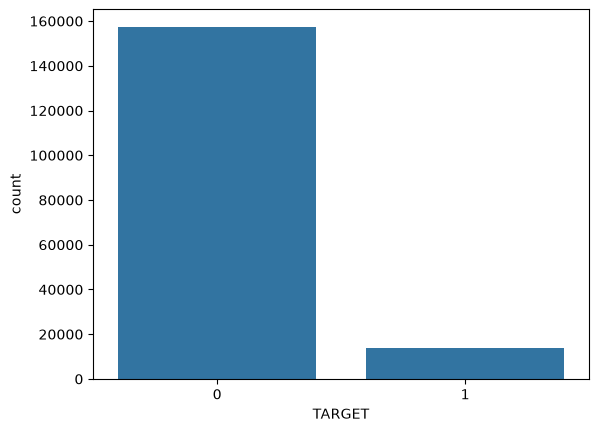

In [13]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()

We can see that the **distribution of the objective variable is highly skewed**. Data in which the distribution of the objective variable is highly skewed in this way is called **unbalanced data**.

When dealing with unbalanced data, we need to be particularly careful in selecting evaluation metrics. For example, if you choose accuracy, you will find that simply predicting all zeros will result in a high accuracy. **Choosing such an inappropriate metric can cause the machine learning model to fail to predict well on new data**.

Another approach to dealing with unbalanced data is to try to balance the distribution of the target variable. The method of reducing the data of the larger target variable is called undersampling, while the method of increasing the data of the smaller objective variable is called oversampling.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable

#### NAME_CONTRACT_TYPE column

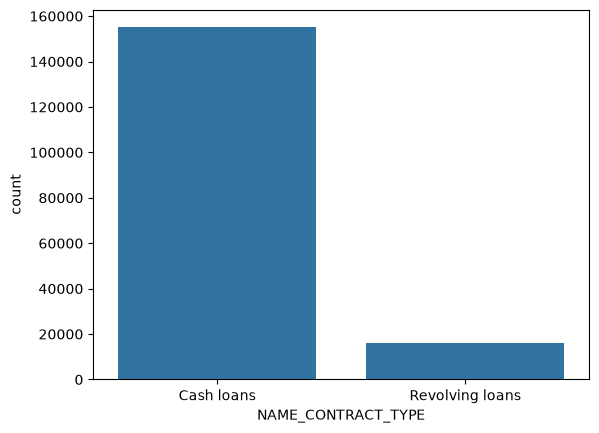

In [14]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

There are two variables in `NAME_CONTRACT_TYPE`, Cash loans and Revolving loans, but they are not evenly distributed. Also, since the machine learning model can only handle data of numeric type, it is necessary to convert the data from string type to numeric type.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable
* Need to convert the data from string type to numeric type

#### ORGANIZATION_TYPE column

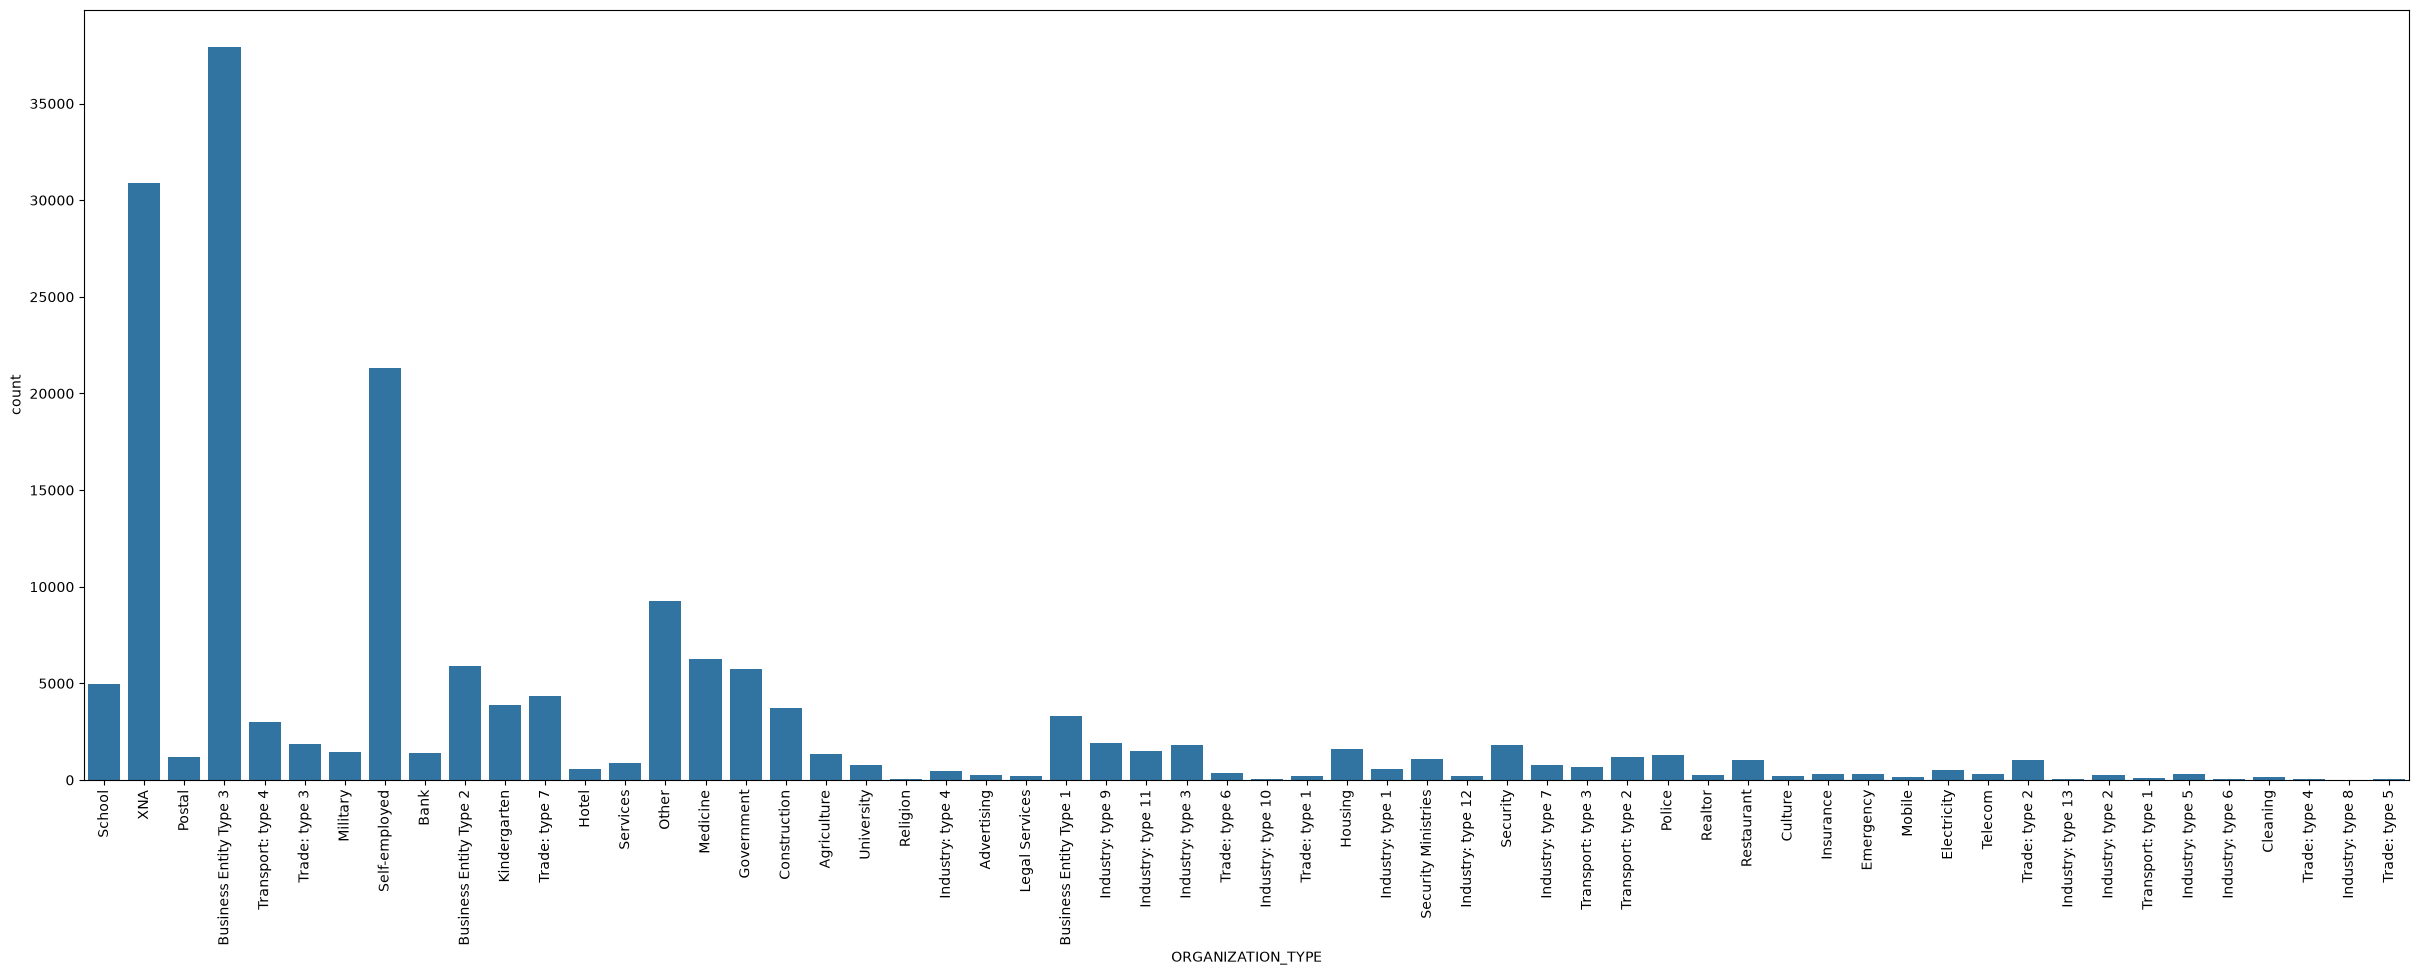

In [15]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different `ORGANIZATION_TYPE`s, and you can also see that there is an ununiformity in the number of data. This is also a string type feature, so it needs to be converted to a numeric type. Also, the second variable from the left is "XNA", which we can infer from its name to be a missing value.


**Findings**:<br>
* Treat "XNA" as missing values
* Need to convert the data from string type to numeric type

#### EXT_SOURCE_2 column

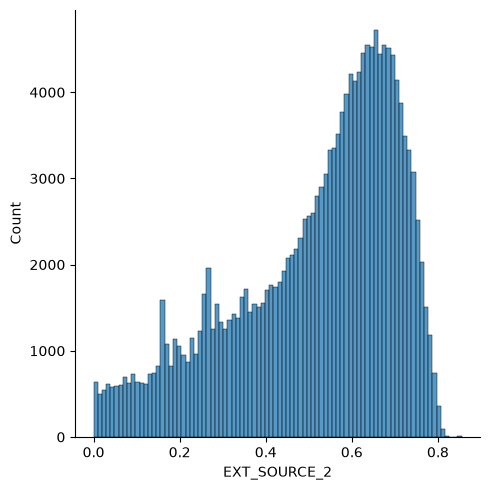

In [16]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

We can see that EXT_SOURCE_2 is normalized between 0 and 1. It seems we can handle this feature as it is.

**Findings**:<br>
* No additional preprocessing is needed
* Need to handle missing values

#### AMT_INCOME_TOTAL column

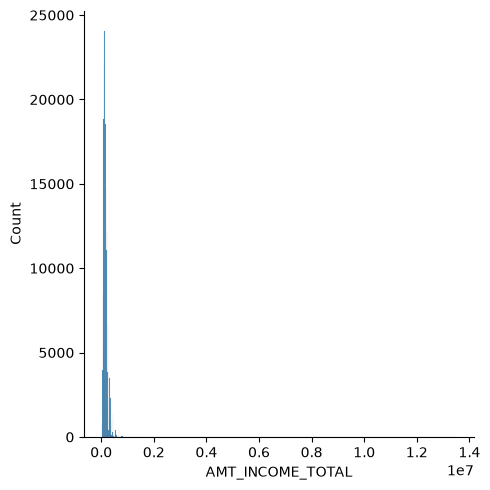

In [17]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret. THis may be caused by the presence of a small number of outliers that take large values. To visualize data like this, a logarithmic transformation can be effective.

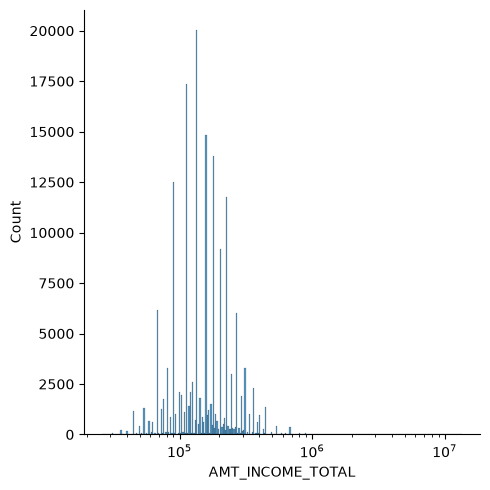

In [18]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()

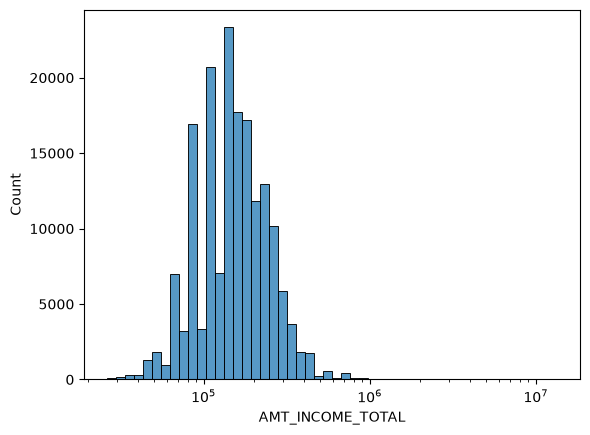

In [19]:
sns.histplot(data=train, x='AMT_INCOME_TOTAL', log_scale=10, bins=50)
plt.show()

We displayed the graph successfully by using logarithmic transformation.
The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [20]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

1641

There are 171202 data in train, but `AMT_INCOME_TOTAL` consists of only 1641 different values. Let's check the top 10 values specifically.

In [21]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

AMT_INCOME_TOTAL
135000.0    19969
112500.0    17320
157500.0    14772
180000.0    13791
90000.0     12481
225000.0    11573
202500.0     9128
67500.0      6130
270000.0     6006
81000.0      3295
Name: count, dtype: int64

It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

**Findings**:<br>
* Should the outlier in the data be addressed?

In [22]:
percentiles = [0.90, 0.95, 0.98, 0.99, 0.995, 0.999, 0.9999, 0.99993, 0.99994, 0.99995, 0.99996, 0.99997, 0.99998, 0.99999, 1.0]
values = train['AMT_INCOME_TOTAL'].quantile(percentiles)

for p, val in zip(percentiles, values):
    print(f"{p*100:6.2f}th percentile: ${val:15,.2f}")

 90.00th percentile: $     270,000.00
 95.00th percentile: $     337,500.00
 98.00th percentile: $     425,959.11
 99.00th percentile: $     463,500.00
 99.50th percentile: $     630,000.00
 99.90th percentile: $     900,000.00
 99.99th percentile: $   2,025,000.00
 99.99th percentile: $   2,250,000.00
 99.99th percentile: $   2,413,786.50
100.00th percentile: $   2,801,200.16
100.00th percentile: $   3,409,191.00
100.00th percentile: $   4,377,573.00
100.00th percentile: $   4,500,000.00
100.00th percentile: $   7,397,977.50
100.00th percentile: $  13,500,000.00


#### OWN_CAR_AGE column

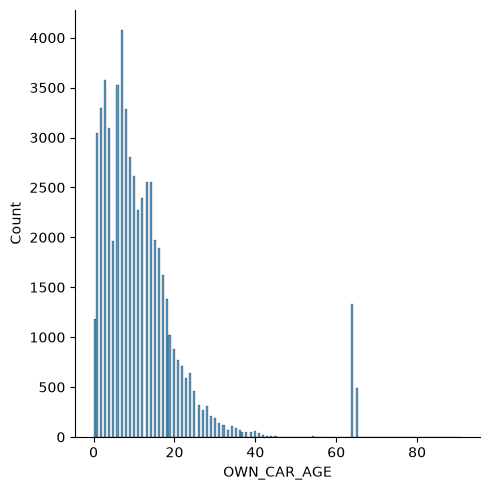

In [23]:
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers.

**Findings**:<br>
* Treat numbers above 60 as outliers

Up to this point, we have visualized and analyzed each feature. I believe that you have realized that visualization requires some ingenuity and that visualization can deepen your understanding of data. I am sure that the visualization and analysis of the 25 features not covered here will lead to improved forecasting accuracy.

### **[Next Steps]**
> + Check for missing values for the features you have added in Section 2.2.
> + Visualize the features you have added. Is the feature categorical or continuous? What type of graph is most effective to understand it?
> + What do you notice about the features? What kind of preprocessing is needed?

## 4.Preprocessing and Feature Creation
Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis.

### TARGET column
The data is heavily skewed, having very few defaults compared to non-default values.

### NAME_CONTRACT_TYPE column
Convert `NAME_CONTRACT_TYPE` to a numeric type. In this case, “Cash loans” is converted to 0 and “Revolving loans” to 1. This method of simply replacing an integer is called **Label Encoding**.

In [24]:
# Numerization of NAME_CONTRACT_TYPE（Label Encoding）
train["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)
test["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)

train.head(5)

,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,CNT_FAM_MEMBERS,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,TARGET
0,0,112500.0,755190.0,36328.5,675000.0,2.0,0.372591,NaN,School,0
1,0,225000.0,585000.0,16893.0,585000.0,2.0,0.449567,NaN,XNA,0
2,0,54000.0,334152.0,18256.5,270000.0,2.0,0.569503,NaN,Postal,0
3,0,67500.0,152820.0,8901.0,135000.0,1.0,0.105235,NaN,XNA,0
4,0,157500.0,271066.5,21546.0,234000.0,2.0,0.202490,NaN,Business Entity Type 3,1


### ORGANIZATION_TYPE column
Convert `ORGANIZATION_TYPE` to a numeric type. This time, we will convert the variable to numeric in terms of the number of data in the variable. For example, if the number of data in “Police” is 1279 and the number of data in “Bank” is 1385, convert “Police” to 1279 and “Bank” to 1385. This method of replacing the number of data with the number of data is called **Count Encoding**.

In [25]:
# Numerization of ORGANIZATION_TYPE (Count Encoding）
organization_ce = train["ORGANIZATION_TYPE"].value_counts()
train["ORGANIZATION_TYPE"] = train["ORGANIZATION_TYPE"].map(organization_ce)
test["ORGANIZATION_TYPE"] = test["ORGANIZATION_TYPE"].map(organization_ce)

train.head(5)

,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,CNT_FAM_MEMBERS,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,TARGET
0,0,112500.0,755190.0,36328.5,675000.0,2.0,0.372591,NaN,4991,0
1,0,225000.0,585000.0,16893.0,585000.0,2.0,0.449567,NaN,30898,0
2,0,54000.0,334152.0,18256.5,270000.0,2.0,0.569503,NaN,1185,0
3,0,67500.0,152820.0,8901.0,135000.0,1.0,0.105235,NaN,30898,0
4,0,157500.0,271066.5,21546.0,234000.0,2.0,0.202490,NaN,37943,1


### EXT_SOURCE_2 column
Fill missing values in `EXT_SOURCE_2`. There are various methods for completing missing values, but in this case, since the number of missing values is small, we simply use the average value to complete the missing values.

**IMPORANT**:
When you fill the missing values in the test data, you need to **fill with the average of the train data**.

In [26]:
# Complete missing values of EXT_SOURCE_2 with the average
train["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
test["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True) # Use average of train data to fill test data

train.isnull().sum()

NAME_CONTRACT_TYPE         0
AMT_INCOME_TOTAL           0
AMT_CREDIT                 0
AMT_ANNUITY                0
AMT_GOODS_PRICE            0
CNT_FAM_MEMBERS            2
EXT_SOURCE_2               0
OWN_CAR_AGE           112992
ORGANIZATION_TYPE          0
TARGET                     0
dtype: int64

### OWN_CAR_AGE column
First, we will replace the unnatural outliers that are over 60 as `np.nan` (missing values).

In [27]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values
train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
test.loc[test["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

Next, we consider the handling of missing values. The original `OWN_CAR_AGE` had 112992 missing values out of 171202 data. With such a large number of missing values, it is difficult and impractical to properly fill the missing values with some value. Therefore, we will group `OWN_CAR_AGE` by decade (e.g. Group 1: 0-9 years, Group 2: 10-19 years, etc.), then apply **One Hot Encoding**.

In [28]:
# Divide OWN_CAR_AGE into groups
train["OWN_CAR_AGE"] = train["OWN_CAR_AGE"] // 10
test["OWN_CAR_AGE"] = test["OWN_CAR_AGE"] // 10

train["OWN_CAR_AGE"].unique()

array([nan,  0.,  2.,  1.,  3.,  4.,  5.])

In [29]:
# Apply One Hot Encoding to OWN_CAR_AGE
train_car_age_ohe = pd.get_dummies(train["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")
test_car_age_ohe = pd.get_dummies(test["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")

# Add the one hot encoded columns to train/test
train = pd.concat([train, train_car_age_ohe], axis=1)
test = pd.concat([test, test_car_age_ohe], axis=1)

# Remove original OWN_CAR_AGE
train.drop('OWN_CAR_AGE', axis=1, inplace=True)
test.drop('OWN_CAR_AGE', axis=1, inplace=True)

train.head(5)

,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,CNT_FAM_MEMBERS,EXT_SOURCE_2,ORGANIZATION_TYPE,TARGET,OWN_CAR_AGE_0.0,OWN_CAR_AGE_1.0,OWN_CAR_AGE_2.0,OWN_CAR_AGE_3.0,OWN_CAR_AGE_4.0,OWN_CAR_AGE_5.0
0,0,112500.0,755190.0,36328.5,675000.0,2.0,0.372591,4991,0,False,False,False,False,False,False
1,0,225000.0,585000.0,16893.0,585000.0,2.0,0.449567,30898,0,False,False,False,False,False,False
2,0,54000.0,334152.0,18256.5,270000.0,2.0,0.569503,1185,0,False,False,False,False,False,False
3,0,67500.0,152820.0,8901.0,135000.0,1.0,0.105235,30898,0,False,False,False,False,False,False
4,0,157500.0,271066.5,21546.0,234000.0,2.0,0.202490,37943,1,False,False,False,False,False,False


### CNT_FAM_MEMBERS column

### Handling Outliers in `CNT_FAM_MEMBERS`

The dataset contains two null values for `CNT_FAM_MEMBERS` so this will be replaced with the median value.

In [30]:
# Impute with median (2.0)
train['CNT_FAM_MEMBERS'] = train['CNT_FAM_MEMBERS'].fillna(train['CNT_FAM_MEMBERS'].median())

### AMT_INCOME_TOTAL column

### 1. Handling Outliers in `AMT_INCOME_TOTAL`

* **Source Column:** `AMT_INCOME_TOTAL` (*"Income of the client"*)
* **Problem:**
  The raw income distribution is heavily right-skewed with extreme outliers (e.g., maximum values exceeding $13,500,000), which severely distorts model loss functions and linear scaling. However, up to the 99.9th percentile ($~900,000 - $1,000,000), values increase smoothly and organically.
* **Solution (Winsorization / Percentile Capping):**
  Instead of dropping high-income applicants, we cap the values at the **99.9th percentile** learned strictly from the training dataset. This retains wealthy applicants as the highest-tier earners while neutralizing extreme mathematical distortions.


In [31]:
# Calculate the 99.9th percentile threshold strictly on training data
income_cap = train['AMT_INCOME_TOTAL'].quantile(0.999)

print(f"Capping AMT_INCOME_TOTAL at 99.9th percentile: ${income_cap:,.2f}")

# Apply clipping to both train and test sets
train['AMT_INCOME_TOTAL'] = train['AMT_INCOME_TOTAL'].clip(upper=income_cap)
test['AMT_INCOME_TOTAL'] = test['AMT_INCOME_TOTAL'].clip(upper=income_cap)

print(f"New Max Income in Train: ${train['AMT_INCOME_TOTAL'].max():,.2f}")
print(f"New Max Income in Test:  ${test['AMT_INCOME_TOTAL'].max():,.2f}")

Capping AMT_INCOME_TOTAL at 99.9th percentile: $900,000.00
New Max Income in Train: $900,000.00
New Max Income in Test:  $900,000.00


### 2. Feature Engineering: Domain Financial Ratios

Raw income alone has limited predictive power; a client's creditworthiness depends on their **ability to pay relative to their obligations and family size**.

Using the official definitions from `HomeCredit_columns_description.xlsx`, we construct 5 standard financial ratios:

1. **`INCOME_CREDIT_PERC`** = `AMT_CREDIT / AMT_INCOME_TOTAL`
   * *Base columns:* `AMT_CREDIT` (*"Credit amount of the loan"*) and `AMT_INCOME_TOTAL` (*"Income of the client"*).
   * *Interpretation:* Debt-to-Income ratio measuring how many years of annual income the loan represents. Higher values indicate greater default risk.

2. **`INCOME_ANNUITY_PERC`** = `AMT_ANNUITY / AMT_INCOME_TOTAL`
   * *Base columns:* `AMT_ANNUITY` (*"Loan annuity"*) and `AMT_INCOME_TOTAL`.
   * *Interpretation:* Payment burden measuring what percentage of income is committed to periodic installments.

3. **`INCOME_PER_PERSON`** = `AMT_INCOME_TOTAL / CNT_FAM_MEMBERS`
   * *Base columns:* `AMT_INCOME_TOTAL` and `CNT_FAM_MEMBERS` (*"How many family members does client have"*).
   * *Interpretation:* Disposable income available per household dependent.

4. **`PAYMENT_RATE`** = `AMT_ANNUITY / AMT_CREDIT`
   * *Base columns:* `AMT_ANNUITY` and `AMT_CREDIT`.
   * *Interpretation:* Repayment velocity reflecting loan term and interest rate structure.

5. **`INCOME_GOODS_PERC`** = `AMT_GOODS_PRICE / AMT_INCOME_TOTAL`
   * *Base columns:* `AMT_GOODS_PRICE` (*"For consumer loans it is the price of the goods for which the loan is given"*) and `AMT_INCOME_TOTAL`.
   * *Interpretation:* Proportion of the financed merchandise cost relative to client income.


In [32]:
# Construct financial ratios for both train and test sets
for df in [train, test]:
    # 1. Credit-to-Income
    df['INCOME_CREDIT_PERC'] = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']

    # 2. Annuity-to-Income
    df['INCOME_ANNUITY_PERC'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']

    # 3. Income per Family Member (safeguarding against 0 or NaN family members)
    fam_count = df['CNT_FAM_MEMBERS'].fillna(1).replace(0, 1)
    df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / fam_count

    # 4. Payment Rate
    df['PAYMENT_RATE'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']

    # 5. Income-to-Goods Price
    df['INCOME_GOODS_PERC'] = df['AMT_GOODS_PRICE'] / df['AMT_INCOME_TOTAL']

# Verify newly created features
ratio_cols = [
    'AMT_INCOME_TOTAL',
    'INCOME_CREDIT_PERC',
    'INCOME_ANNUITY_PERC',
    'INCOME_PER_PERSON',
    'PAYMENT_RATE',
    'INCOME_GOODS_PERC'
]

print("Successfully created financial ratio features.")
display(train[ratio_cols].head())
display(train[ratio_cols].info())


Successfully created financial ratio features.


,AMT_INCOME_TOTAL,INCOME_CREDIT_PERC,INCOME_ANNUITY_PERC,INCOME_PER_PERSON,PAYMENT_RATE,INCOME_GOODS_PERC
0,112500.0,6.712800,0.322920,56250.0,0.048105,6.000000
1,225000.0,2.600000,0.075080,112500.0,0.028877,2.600000
2,54000.0,6.188000,0.338083,27000.0,0.054635,5.000000
3,67500.0,2.264000,0.131867,67500.0,0.058245,2.000000
4,157500.0,1.721057,0.136800,78750.0,0.079486,1.485714


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 6 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   AMT_INCOME_TOTAL     171202 non-null  float64
 1   INCOME_CREDIT_PERC   171202 non-null  float64
 2   INCOME_ANNUITY_PERC  171202 non-null  float64
 3   INCOME_PER_PERSON    171202 non-null  float64
 4   PAYMENT_RATE         171202 non-null  float64
 5   INCOME_GOODS_PERC    171202 non-null  float64
dtypes: float64(6)
memory usage: 7.8 MB


None

### **[Next Steps]**
> + Apply preprocessing to the features you added. Is it correctly preprocessed?
> + Explore other preprocessing methods to apply to the features.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

## 5.Building the Machine Learning Model
Now, we are ready to start building the machine learning model.

### 5.1 Import Additional Libraries
First, we import the necessary libraries for training and evaluation.

- `train_test_split`: Split data into training and evaluation data.
- `StandardScaler`: Standardize the data.
- `roc_auc_score`: Calculate ROC-AUC, the evaluation metric for this competition.

In [33]:
# Importing libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

### 5.2 Preparing the Data
Split the data into explanatory and target variables. The target variable for this dataset is `TARGET` column and the rest are explanatory variables.

In [34]:
# Split the data into explanatory and target variables
X = train.drop("TARGET", axis=1).values
y = train["TARGET"].values
X_test = test.values

Standardize the data. Standardization is the operation of transforming the values so that the mean is 0 and the variance is 1. Some models, such as logistic regression and neural networks, do not learn well without scaling the values in this way.

In [35]:
# Standardization
sc = StandardScaler()
sc.fit(X)
X_std = sc.transform(X)
X_test_std = sc.transform(X_test)

### 5.3 Training the Model
We first split the training data into training data and validation data. This method of keeping a portion of the training data for evaluation and not using it for training is called the **holdout method**. This is one method to approximate the model's predictive ability on unknown data (**generalization** performance).

Here, we will use 70% of the data as training data and 30% as validation data

In [36]:
# Split the original data into the training data and the validation data
X_train, X_valid, y_train, y_valid = train_test_split(X_std, y, test_size=0.3, stratify=y, random_state=0)

Now, let's create models with logistic regression and random forest.

In [37]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=0)
lr.fit(X_train, y_train)

lr_train_pred = lr.predict_proba(X_train)[:, 1]
lr_valid_pred = lr.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, lr_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, lr_valid_pred)}")

Train Score: 0.674915680217793
Valid Score: 0.6769864930563911


In [38]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=0, max_depth=10)
rf.fit(X_train, y_train)

rf_train_pred = rf.predict_proba(X_train)[:, 1]
rf_valid_pred = rf.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, rf_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, rf_valid_pred)}")

Train Score: 0.8049813476219421
Valid Score: 0.7044116758335578


### 5.3.1 LightGBM Model

**LightGBM** (Light Gradient Boosting Machine) is a gradient boosting framework that uses tree-based learning algorithms.
Key advantages over Random Forest for this task:

- **Handles class imbalance** natively via `is_unbalance` or `scale_pos_weight`
- **Built-in categorical feature support** — no need for one-hot encoding
- **Faster training** with histogram-based splitting
- **Better generalization** with leaf-wise tree growth and regularization

Since our dataset has ~8% positive class (highly imbalanced), LightGBM's imbalance handling
is particularly beneficial.

In [ ]:
# LightGBM
import lightgbm as lgb

# LightGBM handles categorical features and missing values natively,
# so we use the UN-standardized data and pass it as a Dataset.
# Re-split from the original (non-scaled) arrays for LightGBM.
X_raw = train.drop("TARGET", axis=1)
y_raw = train["TARGET"].values

# Identify categorical columns for native handling
cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()
for col in cat_cols:
    X_raw[col] = X_raw[col].astype('category')

X_test_raw = test.copy()
for col in cat_cols:
    X_test_raw[col] = X_test_raw[col].astype('category')

# Train / validation split (same ratio & seed as sklearn split)
X_train_lgb, X_valid_lgb, y_train_lgb, y_valid_lgb = train_test_split(
    X_raw, y_raw, test_size=0.3, stratify=y_raw, random_state=0
)

# Create LightGBM datasets
lgb_train = lgb.Dataset(X_train_lgb, label=y_train_lgb,
                        categorical_feature=cat_cols, free_raw_data=False)
lgb_valid = lgb.Dataset(X_valid_lgb, label=y_valid_lgb,
                        categorical_feature=cat_cols, free_raw_data=False,
                        reference=lgb_train)

# Hyperparameters tuned for this imbalanced credit-risk dataset
lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'is_unbalance': True,           # handle class imbalance
    'learning_rate': 0.05,
    'num_leaves': 31,
    'max_depth': -1,                # no limit (leaf-wise growth)
    'min_child_samples': 50,        # regularization against overfitting
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'reg_alpha': 0.1,               # L1 regularization
    'reg_lambda': 1.0,              # L2 regularization
    'random_state': 0,
    'verbose': -1,
}

# Train with early stopping
lgb_model = lgb.train(
    lgb_params,
    lgb_train,
    num_boost_round=1000,
    valid_sets=[lgb_train, lgb_valid],
    valid_names=['train', 'valid'],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100),
    ],
)

# Evaluate
lgb_train_pred = lgb_model.predict(X_train_lgb)
lgb_valid_pred = lgb_model.predict(X_valid_lgb)
print(f"\nLightGBM Train Score: {roc_auc_score(y_train_lgb, lgb_train_pred):.6f}")
print(f"LightGBM Valid Score: {roc_auc_score(y_valid_lgb, lgb_valid_pred):.6f}")

In [ ]:
# Feature importance plot
lgb.plot_importance(lgb_model, max_num_features=15, importance_type='gain',
                    figsize=(10, 6), title='LightGBM Feature Importance (Gain)')
plt.tight_layout()
plt.show()

### 5.3.2 Stratified K-Fold Cross-Validation with LightGBM

A single train/validation split (holdout method) can introduce variance depending on which data points end up in the validation set.
To get a more reliable estimate of generalization performance and to reduce test-time prediction variance,
we apply **Stratified 5-Fold Cross-Validation**:

1. Split the data into 5 stratified folds (preserving the ~8% default rate in each fold).
2. Train 5 separate LightGBM models with early stopping on each fold's validation set.
3. Compute Out-Of-Fold (OOF) predictions to evaluate overall competition metric (ROC-AUC).
4. Average test predictions across all 5 folds to create a robust ensemble prediction.

In [ ]:
# Stratified 5-Fold Cross-Validation with LightGBM
from sklearn.model_selection import StratifiedKFold

n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

oof_preds = np.zeros(len(X_raw))
kfold_test_preds = np.zeros(len(X_test_raw))
fold_models = []
fold_scores = []

feature_names = X_raw.columns.tolist()
feature_importances = pd.DataFrame({'feature': feature_names})

print(f"Starting {n_splits}-Fold Stratified Cross-Validation...\n")

for fold, (trn_idx, val_idx) in enumerate(skf.split(X_raw, y_raw)):
    X_tr, y_tr = X_raw.iloc[trn_idx], y_raw[trn_idx]
    X_va, y_va = X_raw.iloc[val_idx], y_raw[val_idx]
    
    dtrain = lgb.Dataset(X_tr, label=y_tr, categorical_feature=cat_cols, free_raw_data=False)
    dvalid = lgb.Dataset(X_va, label=y_va, categorical_feature=cat_cols, free_raw_data=False, reference=dtrain)
    
    fold_model = lgb.train(
        lgb_params,
        dtrain,
        num_boost_round=1000,
        valid_sets=[dtrain, dvalid],
        valid_names=['train', 'valid'],
        callbacks=[
            lgb.early_stopping(stopping_rounds=50, verbose=False),
            lgb.log_evaluation(period=0)  # silent mode for clean output
        ]
    )
    
    # Out-of-fold and test predictions
    val_pred = fold_model.predict(X_va)
    oof_preds[val_idx] = val_pred
    kfold_test_preds += fold_model.predict(X_test_raw) / n_splits
    
    score = roc_auc_score(y_va, val_pred)
    fold_scores.append(score)
    fold_models.append(fold_model)
    feature_importances[f'fold_{fold+1}'] = fold_model.feature_importance(importance_type='gain')
    
    print(f"Fold {fold + 1}/{n_splits} - Best Iteration: {fold_model.best_iteration:4d} - ROC-AUC: {score:.6f}")

overall_oof_auc = roc_auc_score(y_raw, oof_preds)
print("-" * 55)
print(f"Mean Fold ROC-AUC:      {np.mean(fold_scores):.6f} (+/- {np.std(fold_scores):.6f})")
print(f"Overall OOF ROC-AUC:     {overall_oof_auc:.6f}")

In [ ]:
# Plot average feature importance across folds
feature_importances['mean_importance'] = feature_importances[[f'fold_{i+1}' for i in range(n_splits)]].mean(axis=1)
top_features = feature_importances.sort_values(by='mean_importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x='mean_importance', y='feature', palette='viridis')
plt.title('Top Features by Mean Importance across 5 Folds (Gain)')
plt.xlabel('Mean Gain')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

We find that **LightGBM achieves the best validation score** among all three models, thanks to its gradient boosting approach, native handling of categorical features, and built-in class imbalance support.

### 5.4 (Optional) Ensemble Learning
Now that we have created three models, we can try combining them for better predictive ability (**ensemble learning**). We will average the predictions from all three models, giving equal weight to each.

In [39]:
# Ensemble: average of all three models
# Note: LightGBM uses different train/valid splits (raw data),
# so we ensemble only LR + RF on the standardized split,
# and compare against LightGBM's standalone score.
train_pred = (lr_train_pred + rf_train_pred) / 2
valid_pred = (lr_valid_pred + rf_valid_pred) / 2

print("=== Ensemble (LR + RF) ===")
print(f"Train Score: {roc_auc_score(y_train, train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, valid_pred)}")
print()
print("=== LightGBM (standalone) ===")
print(f"Train Score: {roc_auc_score(y_train_lgb, lgb_train_pred):.6f}")
print(f"Valid Score: {roc_auc_score(y_valid_lgb, lgb_valid_pred):.6f}")

Train Score: 0.7544134848228332
Valid Score: 0.6979558004078499


Compare the LR+RF ensemble against standalone LightGBM. **We will use the LightGBM model as the final model** since gradient boosting typically outperforms simple averaging ensembles on structured/tabular data.

### **[Next Steps]**
> + Is holdout method the best method to evaluate your model?
> + Is the model's hyperparameters optimized? What hyperparameters needs tuning?
> + Explore other models to use to make predictions.
> + Explore other ensembling methods to further improve the model's performance.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

## 6.Creating Prediction Results
Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 6.1 Predicting on the test data
We found that LightGBM achieved the best validation score. Therefore, we will use the LightGBM model to make the final prediction.

```python
# If random forest model was better
pred = rf.predict_proba(X_test_std)[:, 1]
```

In [40]:
# Make predictions for the test data using the LightGBM 5-Fold Ensemble
# Ensembling across folds reduces prediction variance on unseen test data
pred = kfold_test_preds

# (Alternative) If using the single holdout model:
# pred = lgb_model.predict(X_test_raw)

print(f"Predictions generated for {len(pred)} test instances.")
print(f"Prediction statistics - Min: {pred.min():.4f}, Mean: {pred.mean():.4f}, Max: {pred.max():.4f}")

### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [41]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.041595
1,171203,0.119816
2,171204,0.095733
3,171205,0.055061
4,171206,0.194839
...,...,...
61495,232697,0.158165
61496,232698,0.059417
61497,232699,0.102316
61498,232700,0.195186


In [42]:
import os
from datetime import datetime

# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Generate a timestamp string (e.g., 20261020_101915)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Specify the new output file path with the timestamp appended
output_file = output_dir / f"submission_{timestamp}.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)
print(f"Saved: {output_file}")

Saved: /Users/arkarchanmyae/Desktop/projects/gci-competition/output/submission_20261025_160555.csv


That's all for the tutorial of Home Credit Default Risk competition! Submit your CSV file to Omnicampus to see the result.

Only 5 out of 30 features are covered in this notebook, so there are a lot of room for improvement. Check out **[Next Steps]** in each section to see what you can do to improve your score.

### 6.3 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
This section compresses the notebook file (`competition_local.ipynb`) into a ZIP file and saves it to your working directory.
Make sure to save the notebook (Ctrl+S or Cmd+S) before running this cell to include the latest changes.

If you are aiming to become **Honors or Outstanding Student**, you need to submit the ZIP file as well on Omnicampus.

In [43]:
import zipfile

# Define the file names (support both competition.ipynb and competition_local.ipynb)
if (current_dir / "competition.ipynb").exists():
    notebook_filename = "competition.ipynb"
else:
    notebook_filename = "competition_local.ipynb"

zip_filename = "competition_local.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")


Error: Could not find 'competition_local.ipynb' in /Users/arkarchanmyae/Desktop/projects/gci-competition.
Please check if the notebook name and the current directory are correct.
